# Deep Learning, Phase 3 (Sequential Models), Day 6: Forecasting Project, Part 2: LSTM / GRU
Yesterday we set the baselines. Today we build the LSTM and GRU forecasters, compare them **honestly** with those baselines, plot the predictions over time and try a multi-step forecast.

1. Setup (same data and split as Day 5)  2. **Experiment A:** a plain LSTM/GRU on the scaled values  3. **Experiment B:** forecast the *seasonal log-change* instead (a fix for the trend problem)  4. Choose a model on **validation**  5. **Test evaluation, once**  6. Predictions over time  7. Multi-step forecast  8. Discussion

**Rules for today:** every decision (model type, hidden size, layers, which experiment) is made on the **validation** set. The test set is evaluated **once**, at the end, and nothing is changed after seeing it.


In [1]:
import copy, json, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.linear_model import LinearRegression
sns.set_theme(style='whitegrid')
np.random.seed(42); torch.manual_seed(0)

## 1. Setup: the same data, split and scaling as Day 5

In [2]:
df = sns.load_dataset('flights'); df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str), format='%Y-%b')
series = df.set_index('date')['passengers'].astype(float); v = series.values; dates = series.index
n_tr, n_va = 96, 24; n_te = len(v) - n_tr - n_va; K = 12
mu, sd = v[:n_tr].mean(), v[:n_tr].std(); z = (v - mu) / sd                 # scaling statistics from the training part only
def windows(arr, lo, hi): return np.array([arr[i - K:i] for i in range(lo, hi)]), arr[lo:hi]       # targets in [lo, hi); inputs = the K values before
Xtr_p, ytr_p = windows(z, K, n_tr); Xva_p, yva_p = windows(z, n_tr, n_tr + n_va); Xte_p, yte_p = windows(z, n_tr + n_va, len(v))
true_va, true_te = v[n_tr:n_tr + n_va], v[n_tr + n_va:]
def metrics(y_true, y_pred):
    e = y_true - y_pred; return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'MAPE %': 100 * np.abs(e / y_true).mean()}
print('train / validation / test targets:', n_tr - K, '/', n_va, '/', n_te)

train / validation / test targets: 84 / 24 / 24


## 2. Experiment A: a plain LSTM / GRU on the scaled values
This is the straightforward version: input = the last 12 scaled values, output = the next scaled value. The training loop uses **early stopping** on the validation loss (stop when it has not improved for 40 epochs, then restore the best weights) and gradient clipping.

In [3]:
class Net(nn.Module):
    def __init__(self, kind='lstm', hidden=32, layers=1, dropout=0.0):
        super().__init__(); self.rnn = {'lstm': nn.LSTM, 'gru': nn.GRU}[kind](1, hidden, num_layers=layers, batch_first=True, dropout=dropout if layers > 1 else 0.0); self.fc = nn.Linear(hidden, 1)
    def forward(self, x): out, _ = self.rnn(x[..., None]); return self.fc(out[:, -1]).squeeze(1)      # x: (batch, 12) -> (batch, 12, 1)

T = lambda a: torch.tensor(a, dtype=torch.float32)
def fit(Xtr, ytr, Xva, yva, kind='lstm', hidden=32, layers=1, dropout=0.0, seed=0, epochs=400, lr=0.01, patience=40, batch=32):
    torch.manual_seed(seed); m = Net(kind, hidden, layers, dropout); opt = torch.optim.Adam(m.parameters(), lr=lr); lf = nn.MSELoss()
    xtr, ytr_t, xva, yva_t = T(Xtr), T(ytr), T(Xva), T(yva); best, best_state, bad = float('inf'), None, 0
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(xtr))
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]; opt.zero_grad(); lf(m(xtr[idx]), ytr_t[idx]).backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        m.eval()
        with torch.no_grad(): vl = lf(m(xva), yva_t).item()
        if vl < best - 1e-6: best, best_state, bad = vl, copy.deepcopy(m.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(best_state); m.eval(); return m
def predict(m, X):
    with torch.no_grad(): return m(T(X)).numpy()

seeds = [0, 1, 2]; plainA = {}
for kind in ['lstm', 'gru']:
    for s in seeds: plainA[(kind, s)] = fit(Xtr_p, ytr_p, Xva_p, yva_p, kind=kind, seed=s)
rowsA = {k.upper(): [metrics(true_va, predict(plainA[(k, s)], Xva_p) * sd + mu)['MAE'] for s in seeds] for k in ['lstm', 'gru']}
print('Experiment A, validation MAE per seed (passengers):'); display(pd.DataFrame(rowsA, index=[f'seed {s}' for s in seeds]).T.round(2))

Experiment A, validation MAE per seed (passengers):


,seed 0,seed 1,seed 2
LSTM,21.80,23.08,24.56
GRU,23.06,24.99,19.20


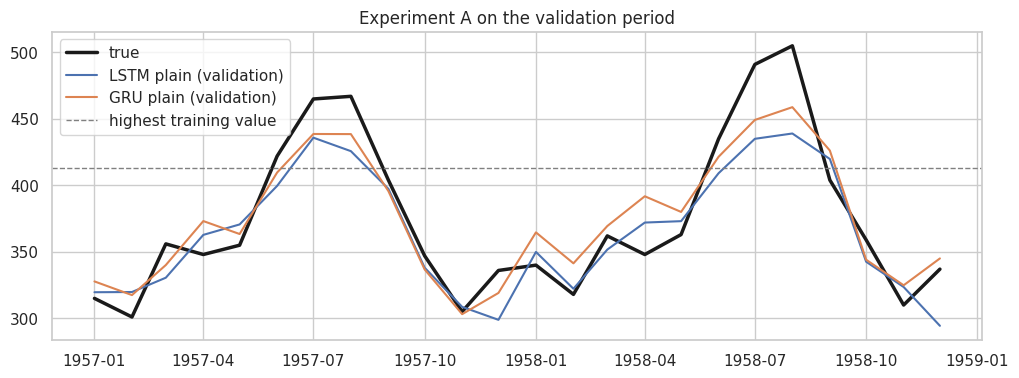

In [4]:
best_plain = {k: min(seeds, key=lambda s: metrics(true_va, predict(plainA[(k, s)], Xva_p) * sd + mu)['MAE']) for k in ['lstm', 'gru']}
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(dates[n_tr:n_tr + n_va], true_va, 'k', lw=2.5, label='true')
for k in ['lstm', 'gru']: ax.plot(dates[n_tr:n_tr + n_va], predict(plainA[(k, best_plain[k])], Xva_p) * sd + mu, label=f'{k.upper()} plain (validation)')
ax.axhline(v[:n_tr].max(), color='grey', ls='--', lw=1, label='highest training value'); ax.legend(); ax.set_title('Experiment A on the validation period'); plt.show()



## 3. Experiment B: forecast the seasonal log-change
The problem with A is the **scale**: the series keeps growing, so the network meets numbers it has never seen. A standard fix is to change what we forecast:

> `d_t = log(passengers_t) - log(passengers_(t-12))` = the growth compared with **the same month last year** (on a log scale).

This number stays on a similar scale all the time (growth of about 0 to 20 percent a year), so the network no longer needs to extrapolate. The log also turns the growing seasonal swings into a constant one. We forecast `d_t` from the last 12 values of `d`, then convert back: **`passengers_t = passengers_(t-12) x exp(d_t)`**.

(Every number used is known at forecast time, and the scaling statistics of `d` again come from the training part only.)

windows  train (72, 12) | validation (24, 12) | test (locked) (24, 12)
average yearly growth in training: 14.5% | spread of d: 0.064


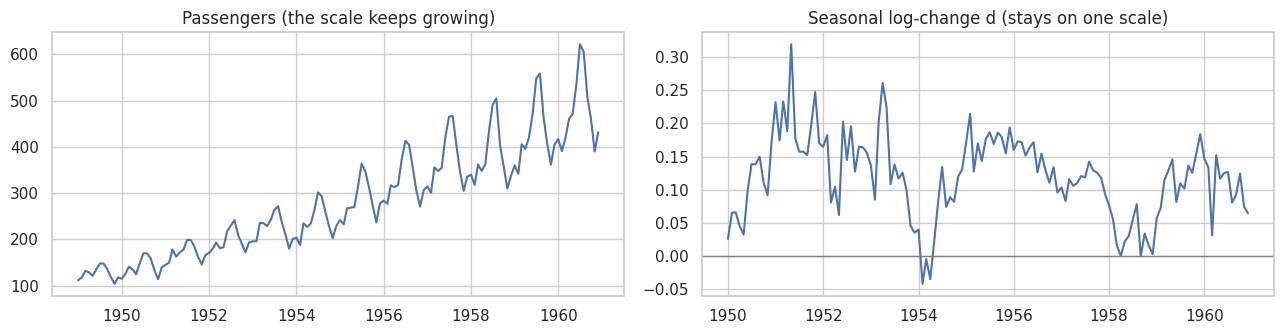

In [5]:
lg = np.log(v); d = np.full(len(v), np.nan); d[12:] = lg[12:] - lg[:-12]                 # seasonal log change; the first 12 months have no value
dm, ds = d[12:n_tr].mean(), d[12:n_tr].std(); dz = (d - dm) / ds                           # scaling from the TRAINING part only
lo_tr = 12 + K                                                                             # first target whose 12 inputs all exist
Xtr_c, ytr_c = windows(dz, lo_tr, n_tr); Xva_c, yva_c = windows(dz, n_tr, n_tr + n_va); Xte_c, yte_c = windows(dz, n_tr + n_va, len(v))
to_pass = lambda p, lo, hi: v[lo - 12:hi - 12] * np.exp(p * ds + dm)                        # back to passengers: last year's value x exp(change)
print('windows  train', Xtr_c.shape, '| validation', Xva_c.shape, '| test (locked)', Xte_c.shape)
print(f'average yearly growth in training: {100 * (np.exp(dm) - 1):.1f}% | spread of d: {ds:.3f}')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5)); ax[0].plot(dates, v); ax[0].set_title('Passengers (the scale keeps growing)'); ax[1].plot(dates[12:], d[12:]); ax[1].axhline(0, color='grey', lw=1); ax[1].set_title('Seasonal log-change d (stays on one scale)'); plt.tight_layout(); plt.show()

### Which baselines belong with Experiment B?
We must be fair: if a simple model also uses this transformation, it might do just as well. So we add two baselines that use it:
- **Seasonal naive x average growth:** last year's value times the average growth seen in training (no learning at all).
- **Linear regression on `d`:** the same inputs as the network, but a linear model.

In [6]:
lin_level = LinearRegression().fit(Xtr_p, ytr_p); lin_d = LinearRegression().fit(Xtr_c, ytr_c)
def baseline_preds(split):
    lo, hi = {'val': (n_tr, n_tr + n_va), 'test': (n_tr + n_va, len(v))}[split]; Xp, Xc = (Xva_p, Xva_c) if split == 'val' else (Xte_p, Xte_c)
    return {'Naive (last month)': Xp[:, -1] * sd + mu, 'Seasonal naive': v[lo - 12:hi - 12], 'Seasonal naive x avg growth': v[lo - 12:hi - 12] * np.exp(dm),
            'Linear regression (levels)': lin_level.predict(Xp) * sd + mu, 'Linear regression (on d)': to_pass(lin_d.predict(Xc), lo, hi)}
bv = baseline_preds('val'); print('Baselines on VALIDATION'); display(pd.DataFrame({k: metrics(true_va, p) for k, p in bv.items()}).T.round(2))

Baselines on VALIDATION


,MAE,RMSE,MAPE %
Naive (last month),35.88,43.98,9.51
Seasonal naive,26.38,31.70,6.95
Seasonal naive x avg growth,24.43,30.47,6.61
Linear regression (levels),18.97,24.07,5.21
Linear regression (on d),11.51,14.84,3.16


### Training LSTM and GRU on `d`: a small grid, chosen on validation
Model type (LSTM or GRU), hidden size (16, 32, 64) and number of layers (1 or 2, with dropout 0.1 between layers). Every configuration is trained with 3 seeds, and we rank them by the **mean validation MAE** in passengers.

In [7]:
grid = [(k, h, L) for k in ['lstm', 'gru'] for h in [16, 32, 64] for L in [1, 2]]; B, rows = {}, []; t0 = time.time()
for (k, h, L) in grid:
    maes = []
    for s in seeds:
        m = fit(Xtr_c, ytr_c, Xva_c, yva_c, kind=k, hidden=h, layers=L, dropout=0.1 if L > 1 else 0.0, seed=s); B[(k, h, L, s)] = m
        maes.append(metrics(true_va, to_pass(predict(m, Xva_c), n_tr, n_tr + n_va))['MAE'])
    rows.append({'model': k.upper(), 'hidden': h, 'layers': L, 'parameters': sum(p.numel() for p in m.parameters()), 'val MAE (mean of 3 seeds)': np.mean(maes), 'min': np.min(maes), 'max': np.max(maes)})
grid_df = pd.DataFrame(rows).sort_values('val MAE (mean of 3 seeds)').reset_index(drop=True); print(f'Grid finished in {time.time() - t0:.0f}s'); display(grid_df.round(2))

Grid finished in 36s


,model,hidden,layers,parameters,val MAE (mean of 3 seeds),min,max
0,GRU,16,2,2561,7.36,6.88,7.81
1,GRU,32,2,9729,7.75,7.59,7.93
2,GRU,16,1,929,7.82,7.35,8.60
3,GRU,64,2,37889,7.86,7.58,8.07
4,GRU,32,1,3393,8.23,8.17,8.31
5,GRU,64,1,12929,8.43,7.59,9.62
6,LSTM,64,1,17217,9.72,9.35,10.08
7,LSTM,32,1,4513,9.89,9.38,10.16
8,LSTM,16,1,1233,10.10,8.82,10.96
9,LSTM,32,2,12961,10.71,9.89,11.81




## 4. Choose the final models (validation only)

In [8]:
best_cfg = grid_df.iloc[0]; bk, bh, bL = best_cfg['model'].lower(), int(best_cfg['hidden']), int(best_cfg['layers'])
seed_val = {s: metrics(true_va, to_pass(predict(B[(bk, bh, bL, s)], Xva_c), n_tr, n_tr + n_va))['MAE'] for s in seeds}; best_seed = min(seed_val, key=seed_val.get)
best_model = B[(bk, bh, bL, best_seed)]
print(f'Experiment B winner: {bk.upper()}, hidden {bh}, layers {bL} | best seed by validation: {best_seed}')
plain_kind = min(['lstm', 'gru'], key=lambda k: np.mean(rowsA[k.upper()])); print(f'Experiment A winner (by mean validation MAE): {plain_kind.upper()}')
vtab = {k: metrics(true_va, p) for k, p in bv.items()}
vtab['A: plain ' + plain_kind.upper()] = metrics(true_va, predict(plainA[(plain_kind, best_plain[plain_kind])], Xva_p) * sd + mu)
vtab[f'B: {bk.upper()} on d (best seed)'] = metrics(true_va, to_pass(predict(best_model, Xva_c), n_tr, n_tr + n_va))
print('VALIDATION summary'); display(pd.DataFrame(vtab).T.round(2))

Experiment B winner: GRU, hidden 16, layers 2 | best seed by validation: 0
Experiment A winner (by mean validation MAE): GRU
VALIDATION summary


,MAE,RMSE,MAPE %
Naive (last month),35.88,43.98,9.51
Seasonal naive,26.38,31.70,6.95
Seasonal naive x avg growth,24.43,30.47,6.61
Linear regression (levels),18.97,24.07,5.21
Linear regression (on d),11.51,14.84,3.16
A: plain GRU,19.20,22.35,5.02
B: GRU on d (best seed),6.88,9.81,1.83


## 5. Test evaluation, once
We freeze everything chosen above and compute the test scores **one time**. For the neural networks we report the **mean over the 3 seeds** of the chosen configuration (and the spread), not only the best seed, because picking the best seed by test score would be cheating.

In [9]:
bt = baseline_preds('test'); ttab = {k: metrics(true_te, p) for k, p in bt.items()}
A_seeds = [metrics(true_te, predict(plainA[(plain_kind, s)], Xte_p) * sd + mu) for s in seeds]
B_seeds = [metrics(true_te, to_pass(predict(B[(bk, bh, bL, s)], Xte_c), n_tr + n_va, len(v))) for s in seeds]
mean_of = lambda lst: {k: np.mean([r[k] for r in lst]) for k in lst[0]}
ttab['A: plain ' + plain_kind.upper() + ' (mean of 3 seeds)'] = mean_of(A_seeds); ttab[f'B: {bk.upper()} on d (mean of 3 seeds)'] = mean_of(B_seeds)
test_df = pd.DataFrame(ttab).T; test_df['MAE min..max over seeds'] = ''
test_df.loc['A: plain ' + plain_kind.upper() + ' (mean of 3 seeds)', 'MAE min..max over seeds'] = f"{min(r['MAE'] for r in A_seeds):.1f} .. {max(r['MAE'] for r in A_seeds):.1f}"
test_df.loc[f'B: {bk.upper()} on d (mean of 3 seeds)', 'MAE min..max over seeds'] = f"{min(r['MAE'] for r in B_seeds):.1f} .. {max(r['MAE'] for r in B_seeds):.1f}"
print('TEST results (passengers, thousands). Lower is better.'); display(test_df.round({'MAE': 2, 'RMSE': 2, 'MAPE %': 2}))

TEST results (passengers, thousands). Lower is better.


,MAE,RMSE,MAPE %,MAE min..max over seeds
Naive (last month),44.21,51.78,9.73,
Seasonal naive,47.58,49.99,10.52,
Seasonal naive x avg growth,14.72,19.09,3.34,
Linear regression (levels),13.49,17.28,3.12,
Linear regression (on d),12.93,16.99,2.79,
A: plain GRU (mean of 3 seeds),53.48,68.57,10.86,49.3 .. 56.9
B: GRU on d (mean of 3 seeds),13.30,18.32,3.03,12.8 .. 13.6




## 6. Predictions over time

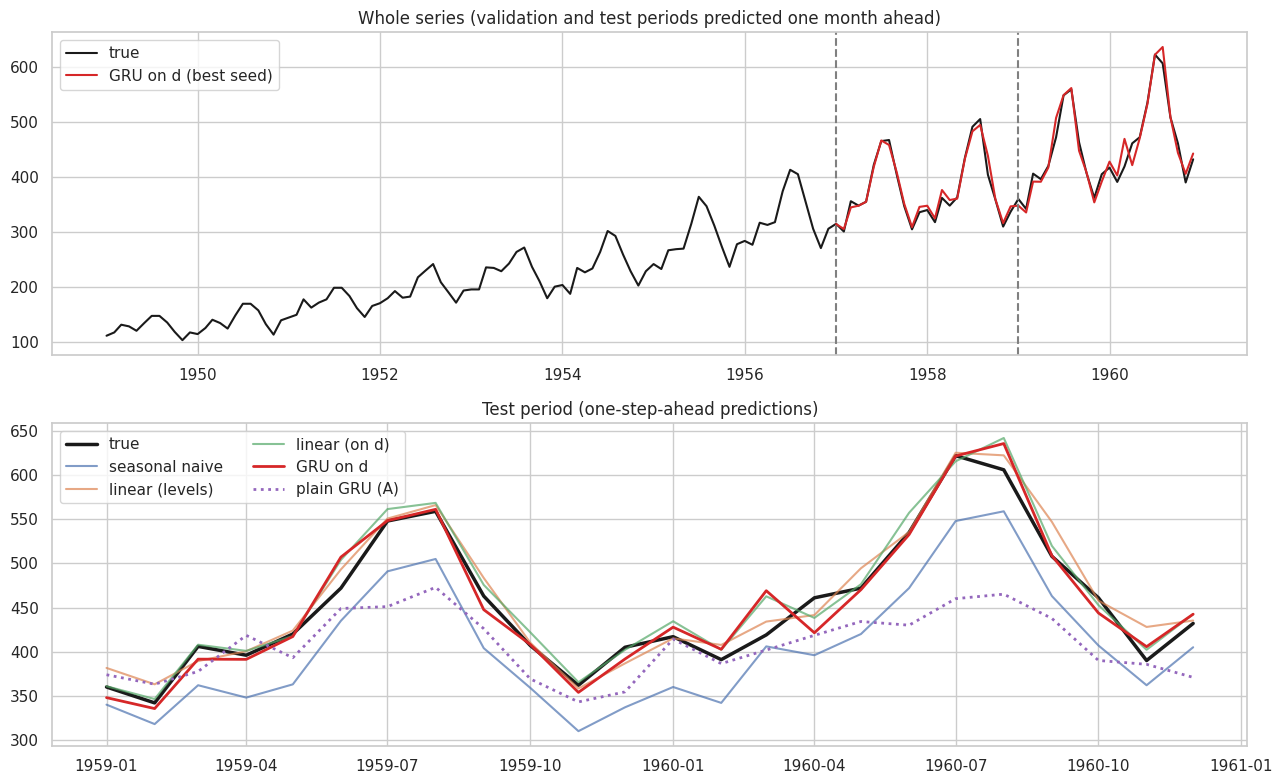

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8))
ax[0].plot(dates, v, color='k', lw=1.5, label='true'); pb = to_pass(predict(best_model, np.vstack([Xva_c, Xte_c])), n_tr, len(v))
ax[0].plot(dates[n_tr:], pb, color='tab:red', label=f'{bk.upper()} on d (best seed)'); ax[0].axvline(dates[n_tr], color='grey', ls='--'); ax[0].axvline(dates[n_tr + n_va], color='grey', ls='--'); ax[0].legend(); ax[0].set_title('Whole series (validation and test periods predicted one month ahead)')
dt = dates[n_tr + n_va:]; ax[1].plot(dt, true_te, 'k', lw=2.5, label='true')
ax[1].plot(dt, bt['Seasonal naive'], alpha=.7, label='seasonal naive'); ax[1].plot(dt, bt['Linear regression (levels)'], alpha=.7, label='linear (levels)'); ax[1].plot(dt, bt['Linear regression (on d)'], alpha=.7, label='linear (on d)')
ax[1].plot(dt, to_pass(predict(best_model, Xte_c), n_tr + n_va, len(v)), color='tab:red', lw=2, label=f'{bk.upper()} on d'); ax[1].plot(dt, predict(plainA[(plain_kind, best_plain[plain_kind])], Xte_p) * sd + mu, color='tab:purple', lw=2, ls=':', label=f'plain {plain_kind.upper()} (A)')
ax[1].legend(ncol=2); ax[1].set_title('Test period (one-step-ahead predictions)'); plt.tight_layout(); plt.show()



## 7. Multi-step forecast
So far we predicted **one month ahead**, using the true past values. A real forecast must look further. We predict `H = 6` months ahead from every starting point in the test period by feeding the model's **own predictions** back as inputs (recursive forecasting), and see how the error grows with the horizon.

,Seasonal naive,Naive (last month),Linear on d,GRU on d,forecasts averaged
1 month(s),47.58,44.21,12.93,12.78,24
2 month(s),48.78,71.52,15.01,16.80,23
3 month(s),49.91,91.55,17.89,19.26,22
4 month(s),50.19,106.67,19.64,20.14,21
5 month(s),50.30,110.40,22.31,18.15,20
6 month(s),49.95,108.63,25.68,18.02,19


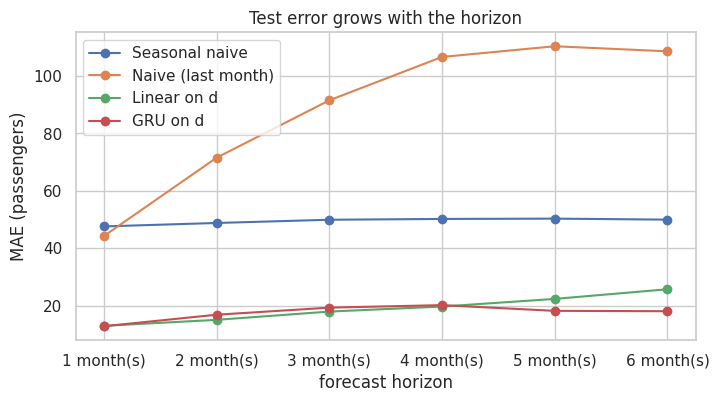

In [11]:
H = 6
def multistep(predict_next, o, H):                      # o = index of the first unknown month; predicts months o .. o+H-1 from information before o
    w = list(dz[o - K:o]); out = []
    for h in range(H):
        nxt = predict_next(np.array(w[-K:])); w.append(nxt); out.append(v[o + h - 12] * np.exp(nxt * ds + dm))       # v[o+h-12] is last year's value: already known for h < 12
    return np.array(out)
nn_next = lambda w: float(best_model(T(w[None, :])).item()); lin_next = lambda w: float(lin_d.predict(w[None, :])[0])
errs = {k: [[] for _ in range(H)] for k in ['Seasonal naive', 'Naive (last month)', 'Linear on d', f'{bk.upper()} on d']}
for o in range(n_tr + n_va, len(v)):
    f_nn, f_lin = multistep(nn_next, o, H), multistep(lin_next, o, H)
    for h in range(H):
        idx = o + h
        if idx >= len(v): break
        errs['Seasonal naive'][h].append(abs(v[idx] - v[idx - 12])); errs['Naive (last month)'][h].append(abs(v[idx] - v[o - 1])); errs['Linear on d'][h].append(abs(v[idx] - f_lin[h])); errs[f'{bk.upper()} on d'][h].append(abs(v[idx] - f_nn[h]))
mh = pd.DataFrame({k: [np.mean(e) for e in lst] for k, lst in errs.items()}, index=[f'{h + 1} month(s)' for h in range(H)]); mh['forecasts averaged'] = [len(errs['Naive (last month)'][h]) for h in range(H)]
display(mh.round(2)); mh.drop(columns='forecasts averaged').plot(marker='o', figsize=(8, 4)); plt.ylabel('MAE (passengers)'); plt.xlabel('forecast horizon'); plt.title('Test error grows with the horizon'); plt.show()

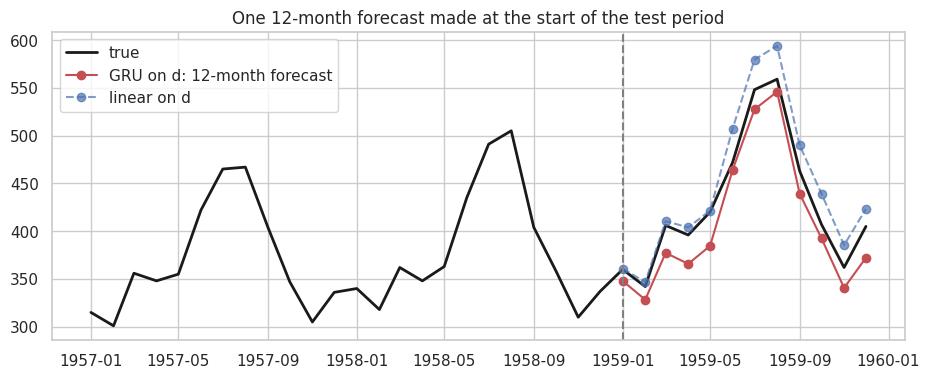

In [12]:
o = n_tr + n_va; f = multistep(nn_next, o, 12); fl = multistep(lin_next, o, 12)
plt.figure(figsize=(11, 4)); plt.plot(dates[o - 24:o + 12], v[o - 24:o + 12], 'k', lw=2, label='true'); plt.plot(dates[o:o + 12], f, 'r-o', label=f'{bk.upper()} on d: 12-month forecast'); plt.plot(dates[o:o + 12], fl, 'b--o', alpha=.7, label='linear on d')
plt.axvline(dates[o], color='grey', ls='--'); plt.legend(); plt.title('One 12-month forecast made at the start of the test period'); plt.show()



## 8. Save the model (for the app on Day 7)
We save the chosen model and everything needed to use it later (scaling numbers and configuration).

In [13]:
torch.save(best_model.state_dict(), 'forecaster.pt')
meta = {'kind': bk, 'hidden': bh, 'layers': bL, 'dropout': 0.1 if bL > 1 else 0.0, 'K': K, 'dm': float(dm), 'ds': float(ds), 'target': 'seasonal log change: log(y_t) - log(y_(t-12))', 'trained_on': 'airline passengers 1949-1956 (train part only)'}
json.dump(meta, open('forecaster_meta.json', 'w'), indent=2); print(meta)
chk = Net(bk, bh, bL, meta['dropout']); chk.load_state_dict(torch.load('forecaster.pt')); chk.eval()
print('Reloaded model gives the same predictions?', np.allclose(predict(chk, Xte_c), predict(best_model, Xte_c), atol=1e-6))

{'kind': 'gru', 'hidden': 16, 'layers': 2, 'dropout': 0.1, 'K': 12, 'dm': 0.13546433055430138, 'ds': 0.06376847222590205, 'target': 'seasonal log change: log(y_t) - log(y_(t-12))', 'trained_on': 'airline passengers 1949-1956 (train part only)'}
Reloaded model gives the same predictions? True
